# LAB 09 — Bias, Variance and Imbalanced Data
## Overfitting, ROC/AUC, Resampling, SMOTE and Noisy Data on Real Medical Data

## Student Information
- **Name:**
- **Student ID:**
- **Section:**
- **GitHub:**
- **Kaggle:**
- **Dataset:** Stroke Prediction Dataset (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

### Before You Start
- You already know the models, scaling, splitting and cross-validation from Labs 3-8. This lab does not re-teach them.
- Every task ends with a question about **your own results**. A table or plot without a written interpretation earns no marks.
- Use `SEED = 42` everywhere. **Golden rule:** anything that learns from data (scaler, imputer, resampler, threshold) is learned from the **training data only**.
- Install once if needed: `pip install imbalanced-learn`


---

## Part 0 — Setup and the Data
A hospital wants to flag patients at risk of stroke from routine information. Target: `stroke` (1 = had a stroke, 0 = did not).

**What to do:**
1. Import everything you need (including `imblearn`) and set `SEED = 42`.
2. Load the CSV. Report the shape, the columns with missing values, the value counts of `gender`, and the number of patients with `stroke = 1` and `stroke = 0` (count and %).
3. Clean: remove the identifier column; remove any `gender` category with too few rows to learn or test; apply categorical encoding (`pd.get_dummies`) to the text columns.
4. Split 80/20 with `stratify=y`, `random_state=SEED`. Fill missing numeric values with a median learned from the **train** set only. Make a scaled copy (`StandardScaler` fitted on train) for Logistic Regression.
5. Report the number of stroke cases in the train and in the test set.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_val_predict, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# ---- load the CSV (local copy first, then Colab path, then a public mirror)
candidates = ["healthcare-dataset-stroke-data.csv",
              "/content/healthcare-dataset-stroke-data.csv",
              "/content/drive/MyDrive/healthcare-dataset-stroke-data.csv"]
path = next((p for p in candidates if os.path.exists(p)),
            "https://raw.githubusercontent.com/Api579/stroke-prediction-ml/main/healthcare-dataset-stroke-data.csv")
df = pd.read_csv(path)

print("Shape:", df.shape)
print("\nColumns with missing values:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nValue counts of gender:")
print(df["gender"].value_counts())
print("\nStroke counts:")
counts = df["stroke"].value_counts()
for k in [1, 0]:
    print(f"stroke = {k}: {counts[k]:5d}  ({counts[k] / len(df) * 100:.2f}%)")


Shape: (5110, 12)

Columns with missing values:
bmi    201
dtype: int64

Value counts of gender:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke counts:
stroke = 1:   249  (4.87%)
stroke = 0:  4861  (95.13%)


In [2]:
# ---- clean
df = df.drop(columns="id")                      # identifier, carries no medical information
df = df[df["gender"] != "Other"].reset_index(drop=True)   # 1 row only: cannot be learned or tested
df = pd.get_dummies(df, drop_first=True)        # text columns -> 0/1 columns

y = df["stroke"]
X = df.drop(columns="stroke").astype(float)
print("Feature matrix:", X.shape)
print("Columns:", list(X.columns))

# ---- split 80/20, stratified
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

# ---- median learned from TRAIN only
train_median = X_train.median()
X_train = X_train.fillna(train_median)
X_test = X_test.fillna(train_median)
print("\nMissing values left (train / test):", X_train.isna().sum().sum(), "/", X_test.isna().sum().sum())

# ---- scaled copy for Logistic Regression (scaler fitted on TRAIN only)
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("\nTrain rows:", len(X_train), "| stroke cases in train:", int(y_train.sum()),
      f"({y_train.mean() * 100:.2f}%)")
print("Test rows: ", len(X_test), "| stroke cases in test: ", int(y_test.sum()),
      f"({y_test.mean() * 100:.2f}%)")


Feature matrix: (5109, 15)
Columns: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Male', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']

Missing values left (train / test): 0 / 0

Train rows: 4087 | stroke cases in train: 199 (4.87%)
Test rows:  1022 | stroke cases in test:  50 (4.89%)


**Question 0.1:** In 2–3 lines: how imbalanced is the data? Why did we use `stratify=y`, and what could go wrong with only a few stroke cases in the test set?

**Your answer:**

The data is strongly imbalanced: only 249 of 5,110 patients (4.87%) had a stroke, about 1 stroke for every 20 patients. `stratify=y` makes the train and test sets keep the same 4.9% stroke rate (199 strokes in train = 4.87%, 50 in test = 4.89%). Without it, a random split could put noticeably fewer or more strokes in the test set than expected.

With only about 50 stroke cases in the test set, every metric that depends on them is very unstable: one patient is 2 percentage points of recall, and precision and PR AUC can swing a lot on a handful of predictions. A split with very few strokes in the test set could give a misleadingly good or bad score purely by luck.


---

## Part 1 — The Accuracy Trap
**Objective:** show that a model can have excellent accuracy and still be useless.
1. Build a baseline that always predicts the majority class (`DummyClassifier(strategy='most_frequent')`). Report accuracy.
2. Train a default Logistic Regression on the scaled training data. Report Accuracy, Precision, Recall, F1, ROC AUC and PR AUC (average precision) on the test set, and print the confusion matrix.
3. Write a helper function that takes a model and train/test data and returns these six metrics (you will reuse it all lab).

In [3]:
def evaluate(model, Xtr, ytr, Xte, yte, threshold=0.5, fit=True):
    """Fit (optionally) and return the six metrics on the test set."""
    if fit:
        model.fit(Xtr, ytr)
    proba = model.predict_proba(Xte)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy":  accuracy_score(yte, pred),
        "Precision": precision_score(yte, pred, zero_division=0),
        "Recall":    recall_score(yte, pred, zero_division=0),
        "F1":        f1_score(yte, pred, zero_division=0),
        "ROC AUC":   roc_auc_score(yte, proba),
        "PR AUC":    average_precision_score(yte, proba),
    }

# ---- baseline: always predict "no stroke"
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
base = evaluate(dummy, X_train, y_train, X_test, y_test, fit=False)
print("Baseline (always 'no stroke') accuracy: %.4f" % base["Accuracy"])
print(pd.Series(base).round(4))


Baseline (always 'no stroke') accuracy: 0.9511
Accuracy     0.9511
Precision    0.0000
Recall       0.0000
F1           0.0000
ROC AUC      0.5000
PR AUC       0.0489
dtype: float64


Default Logistic Regression (scaled data), test set:
Accuracy     0.9521
Precision    1.0000
Recall       0.0200
F1           0.0392
ROC AUC      0.8394
PR AUC       0.2692
dtype: float64

Confusion matrix  [[TN FP]
                   [FN TP]]
[[972   0]
 [ 49   1]]


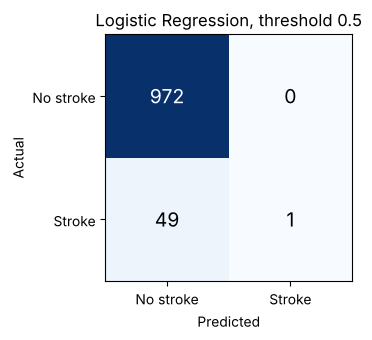

In [4]:
lr = LogisticRegression(max_iter=1000, random_state=SEED)
lr_metrics = evaluate(lr, X_train_s, y_train, X_test_s, y_test)

print("Default Logistic Regression (scaled data), test set:")
print(pd.Series(lr_metrics).round(4))

cm = confusion_matrix(y_test, lr.predict(X_test_s))
print("\nConfusion matrix  [[TN FP]\n                   [FN TP]]")
print(cm)

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["No stroke", "Stroke"]); ax.set_yticklabels(["No stroke", "Stroke"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Logistic Regression, threshold 0.5")
plt.tight_layout(); plt.show()


**Question 1.1:** Compare the accuracy of the baseline and of Logistic Regression. What do you conclude?

**Question 1.2:** Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?

**Your answer:**

**Q1.1.** The "always no stroke" baseline gets an accuracy of **0.9511**, and the default Logistic Regression gets **0.9521**, a difference of 0.001 (one patient). The trained model is not meaningfully better than a model that never detects a stroke. Accuracy mostly counts the healthy majority, so with 95% healthy patients a useless model already looks excellent.

**Q1.2.** The confusion matrix is TN = 972, FP = 0, FN = 49, TP = 1, so recall is only **0.02** (1 of 50 strokes found). A false negative means a patient who has a high stroke risk is told "you are fine", so there is no follow-up or prevention. That is the most costly error for the hospital. Instead of accuracy we should trust **recall** (how many strokes we catch), **precision** and **F1** for the stroke class, and the threshold-free **ROC AUC (0.839)** and **PR AUC (0.269 against a no-skill level of 0.049)**. Note that the precision of 1.0 is based on a single flagged patient, so it means almost nothing.


---

## Part 2 — Underfitting, Overfitting, Bias and Variance
Use **ROC AUC** (not accuracy) as the score from now on.

### Task 2.1 — Validation curve
For `max_depth` = 1, 2, …, 15 and `None`, record the train ROC AUC and the 5-fold stratified CV ROC AUC (train data only). Plot both curves on one chart (labels, title, legend) and report the best depth by CV AUC.

           Train AUC  CV AUC
max_depth                   
1             0.7171  0.7317
2             0.8208  0.8168
3             0.8375  0.8161
4             0.8580  0.8180
5             0.8758  0.7921
6             0.9026  0.7585
7             0.9276  0.7385
8             0.9494  0.7138
9             0.9678  0.6812
10            0.9808  0.6414
11            0.9910  0.6108
12            0.9959  0.6126
13            0.9985  0.5955
14            0.9996  0.5889
15            0.9999  0.5779
None          1.0000  0.5644

Best depth by CV AUC: 4 -> CV AUC = 0.8180


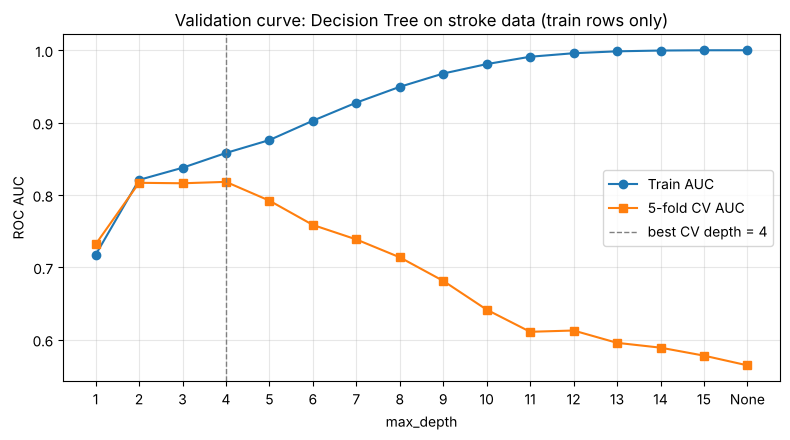

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depths = list(range(1, 16)) + [None]
labels = [str(d) for d in depths]

val_rows = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    tree.fit(X_train, y_train)
    train_auc = roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1])
    cv_auc = cross_val_score(tree, X_train, y_train, cv=skf, scoring="roc_auc").mean()
    val_rows.append({"max_depth": str(d), "Train AUC": train_auc, "CV AUC": cv_auc})
val_df = pd.DataFrame(val_rows).set_index("max_depth")
print(val_df.round(4))

best_depth = val_df["CV AUC"].idxmax()
print("\nBest depth by CV AUC:", best_depth, "-> CV AUC = %.4f" % val_df.loc[best_depth, "CV AUC"])

plt.figure(figsize=(8, 4.5))
plt.plot(labels, val_df["Train AUC"], "o-", label="Train AUC")
plt.plot(labels, val_df["CV AUC"], "s-", label="5-fold CV AUC")
plt.axvline(labels.index(best_depth), color="gray", ls="--", lw=1, label=f"best CV depth = {best_depth}")
plt.xlabel("max_depth"); plt.ylabel("ROC AUC")
plt.title("Validation curve: Decision Tree on stroke data (train rows only)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


### Task 2.2 — Learning curves
Use `learning_curve` (`scoring='roc_auc'`, train sizes 20%→100%) for a tree with `max_depth=1` and a tree with `max_depth=None`. Plot train and CV AUC against the number of training rows, side by side.

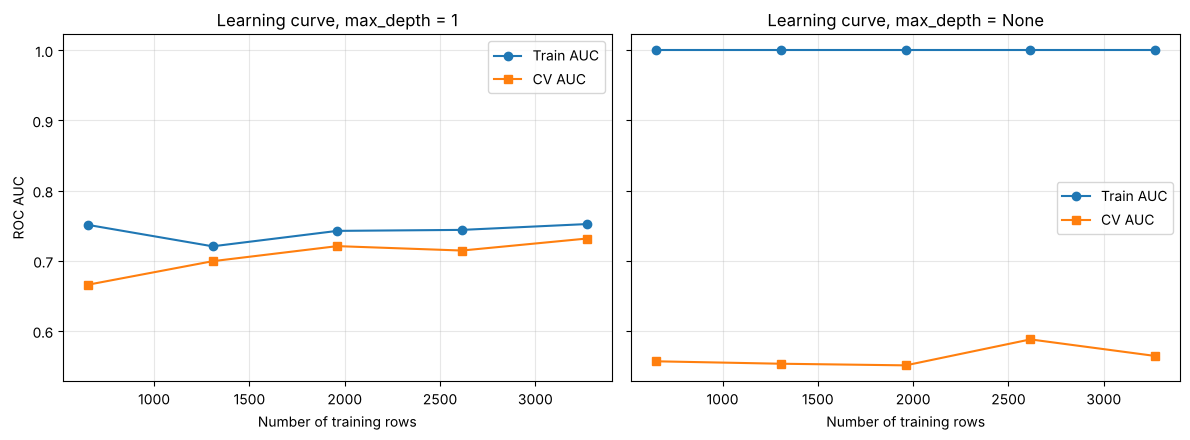

max_depth  train rows  Train AUC  CV AUC    gap
        1         653     0.7512  0.6659 0.0853
        1        1307     0.7206  0.6994 0.0212
        1        1961     0.7426  0.7209 0.0217
        1        2615     0.7440  0.7146 0.0294
        1        3269     0.7523  0.7317 0.0206
     None         653     1.0000  0.5568 0.4432
     None        1307     1.0000  0.5533 0.4467
     None        1961     1.0000  0.5510 0.4490
     None        2615     1.0000  0.5880 0.4120
     None        3269     1.0000  0.5644 0.4356


In [6]:
sizes = np.linspace(0.2, 1.0, 5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
lc_summary = []
for ax, d in zip(axes, [1, None]):
    tr_sizes, tr_sc, va_sc = learning_curve(
        DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train,
        train_sizes=sizes, cv=skf, scoring="roc_auc", shuffle=True, random_state=SEED)
    ax.plot(tr_sizes, tr_sc.mean(axis=1), "o-", label="Train AUC")
    ax.plot(tr_sizes, va_sc.mean(axis=1), "s-", label="CV AUC")
    ax.set_title(f"Learning curve, max_depth = {d}")
    ax.set_xlabel("Number of training rows"); ax.grid(alpha=0.3); ax.legend()
    for n, a, b in zip(tr_sizes, tr_sc.mean(axis=1), va_sc.mean(axis=1)):
        lc_summary.append({"max_depth": str(d), "train rows": int(n), "Train AUC": a, "CV AUC": b,
                           "gap": a - b})
axes[0].set_ylabel("ROC AUC")
plt.tight_layout(); plt.show()
print(pd.DataFrame(lc_summary).round(4).to_string(index=False))


### Task 2.3 — Measure variance directly
Variance = if the training data changes a little, how much do the predictions change?
1. For `max_depth` = 1, 3 and `None`: draw **40 bootstrap samples** of the train rows (with replacement, same size), fit a tree on each, and collect each tree's predicted stroke probability for every test patient.
2. For every test patient compute the variance of its 40 probabilities, then average over patients. Also report the mean test ROC AUC of the 40 trees and the ROC AUC of the **averaged** prediction.
3. Show the three depths in one table.

*Hints:* `rng.choice(len(X_train), len(X_train), replace=True)` and `X_train.iloc[idx]`; collect an array of shape (40, n_test); `probs.var(axis=0)`.

In [7]:
rng = np.random.default_rng(SEED)
B = 40
var_rows = []
for d in [1, 3, None]:
    probs = np.zeros((B, len(X_test)))
    single_aucs = []
    for b in range(B):
        idx = rng.choice(len(X_train), len(X_train), replace=True)       # bootstrap sample
        tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
        tree.fit(X_train.iloc[idx], y_train.iloc[idx])
        probs[b] = tree.predict_proba(X_test)[:, 1]
        single_aucs.append(roc_auc_score(y_test, probs[b]))
    var_rows.append({
        "max_depth": str(d),
        "Mean variance of prediction": probs.var(axis=0).mean(),
        "Mean AUC of single trees": np.mean(single_aucs),
        "AUC of averaged prediction": roc_auc_score(y_test, probs.mean(axis=0)),
    })
var_df = pd.DataFrame(var_rows).set_index("max_depth")
print(var_df.round(4))


           Mean variance of prediction  Mean AUC of single trees  AUC of averaged prediction
max_depth                                                                                   
1                               0.0007                    0.7623                      0.8132
3                               0.0017                    0.7964                      0.8343
None                            0.0420                    0.5552                      0.7566


**Question 2.1:** From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote train and CV AUC for one depth in each zone.

**Question 2.2:** From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one?

**Question 2.3:** From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does (Lab 4).

**Question 2.4:** In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit?

**Your answer:**

**Q2.1.** *Underfitting (high bias):* depth 1 has train AUC 0.717 and CV AUC 0.732. Both are low and there is no gap, so the tree is too simple. *Good zone:* depths 2 to 4 (CV AUC 0.817, 0.816, 0.818). *Overfitting (high variance):* from about depth 5 onward the train AUC keeps rising while the CV AUC falls. At depth 10 the train AUC is 0.981 against a CV AUC of 0.641, and with no limit the train AUC is 1.000 against a CV AUC of only 0.564. The best depth by CV AUC is **4** (0.818), but depths 2, 3 and 4 differ by less than 0.002, so I would choose depth 3 (train 0.838, CV 0.816) as the simplest tree in that plateau.

**Q2.2.** *High bias:* train and CV curves are both low and close together. For depth 1 they end at 0.752 (train) and 0.732 (CV), a gap of only 0.02, and both are flat. *High variance:* the train curve is very high and the CV curve is far below it. For `max_depth=None` the train AUC is 1.000 and the CV AUC is 0.55 to 0.59, a gap of about 0.44. More rows will not fix high bias: the depth-1 tree cannot represent more, so its curves stay flat at about 0.73 to 0.75. More rows can only slowly reduce variance, and here the unlimited tree barely moved (CV AUC 0.557 with 653 rows, 0.564 with 3,269 rows, gap still about 0.44). The better fix for variance is limiting depth, regularisation or averaging many trees.

**Q2.3.** Variance grows strongly with depth: mean prediction variance is 0.0007 for depth 1, 0.0017 for depth 3 and 0.0420 for no limit, about 60 times more than depth 1. Averaging the 40 trees improves the AUC at every depth: 0.762 to 0.813 (depth 1), 0.796 to 0.834 (depth 3) and 0.555 to 0.757 (no limit). The biggest gain (+0.20) is for the high-variance deep tree, because averaging cancels the errors that are random from sample to sample. This is exactly what Random Forest does: it grows many deep, high-variance trees on bootstrap samples (plus random feature subsets) and averages them, so variance drops while bias stays low. Averaging cannot remove bias, which is why the averaged depth-1 trees are still behind the averaged depth-3 trees.

**Q2.4.** Total error is made of bias, variance and unavoidable noise. A simple model has high bias and low variance (underfits). A complex model has low bias and high variance (overfits). Making the model more complex lowers bias but raises variance, so the test error is U-shaped and the best model sits in the middle. **Depth 1** is high bias and low variance (variance 0.0007, single-tree AUC 0.762). **Depth 3** is a good balance (variance 0.0017, best single-tree AUC 0.796). **Depth None** has almost no bias (train AUC 1.0) but very high variance (0.0420), and its single-tree test AUC of 0.555 is close to random guessing.


---

## Part 3 — ROC, AUC, Precision-Recall and Thresholds
### Task 3.1 — Compare models with curves
1. Train Logistic Regression (scaled), Decision Tree (`max_depth=3`) and Random Forest (200 trees, `min_samples_leaf=5`, `random_state=SEED`) on the original training data.
2. Draw the ROC curves of the three models on one chart (AUC in the legend, random-guessing diagonal).
3. Draw the Precision-Recall curves on a second chart. Add a horizontal **no-skill line** (the stroke rate) and put the average precision in the legend.

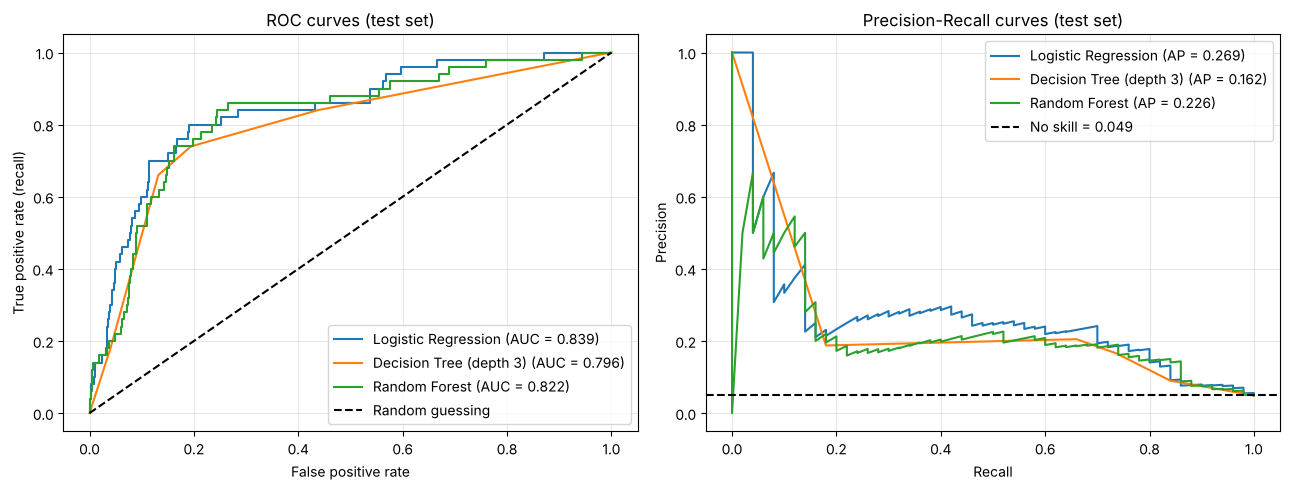

                         ROC AUC  PR AUC
Logistic Regression       0.8394  0.2692
Decision Tree (depth 3)   0.7956  0.1621
Random Forest             0.8224  0.2255


In [8]:
lr3 = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_s, y_train)
dt3 = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)
rf3 = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1).fit(X_train, y_train)

proba3 = {
    "Logistic Regression": lr3.predict_proba(X_test_s)[:, 1],
    "Decision Tree (depth 3)": dt3.predict_proba(X_test)[:, 1],
    "Random Forest": rf3.predict_proba(X_test)[:, 1],
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in proba3.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random guessing")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves (test set)"); axes[0].legend(loc="lower right"); axes[0].grid(alpha=0.3)

for name, p in proba3.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", label=f"No skill = {y_test.mean():.3f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curves (test set)"); axes[1].legend(loc="upper right"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(pd.DataFrame({n: {"ROC AUC": roc_auc_score(y_test, p), "PR AUC": average_precision_score(y_test, p)}
                    for n, p in proba3.items()}).T.round(4))


### Task 3.2 — Choose a decision threshold
The hospital wants to catch **at least 80%** of strokes.
1. Using **only the training data**, get out-of-fold probabilities for Logistic Regression (`cross_val_predict(..., method='predict_proba')`), then find the highest threshold that gives recall ≥ 0.80 on them.
2. Apply that threshold to the **test** probabilities. Report test recall, precision, the confusion matrix, how many patients are flagged and how many are false alarms.

In [9]:
# 1) out-of-fold probabilities on TRAIN only (scaler inside the pipeline, so it is refitted in every fold)
lr_pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
oof = cross_val_predict(lr_pipe, X_train, y_train, cv=skf, method="predict_proba")[:, 1]

fpr, tpr, thr = roc_curve(y_train, oof)
ok = tpr >= 0.80
threshold = thr[ok].max()          # highest threshold that still gives recall >= 0.80
print("Out-of-fold recall at chosen threshold: %.3f" % recall_score(y_train, oof >= threshold))
print("Chosen threshold: %.4f" % threshold)

# 2) apply it to the TEST probabilities of the Part 3.1 Logistic Regression
p_test = proba3["Logistic Regression"]
pred_t = (p_test >= threshold).astype(int)
cm_t = confusion_matrix(y_test, pred_t)
tn, fp, fn, tp = cm_t.ravel()
print("\nTest recall   : %.3f" % recall_score(y_test, pred_t))
print("Test precision: %.3f" % precision_score(y_test, pred_t))
print("Confusion matrix:\n", cm_t)
print(f"Patients flagged: {pred_t.sum()} out of {len(y_test)}  ({pred_t.mean() * 100:.1f}%)")
print(f"  true strokes caught: {tp}   missed strokes: {fn}   false alarms: {fp}")
print(f"  about {fp / tp:.1f} false alarms for every stroke caught")


Out-of-fold recall at chosen threshold: 0.804
Chosen threshold: 0.0509

Test recall   : 0.820
Test precision: 0.135
Confusion matrix:
 [[710 262]
 [  9  41]]
Patients flagged: 303 out of 1022  (29.6%)
  true strokes caught: 41   missed strokes: 9   false alarms: 262
  about 6.4 false alarms for every stroke caught


**Question 3.1:** In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is far above 0.5. How can both be true? What does AUC measure, and what does the 0.5 threshold have to do with it?

**Question 3.2:** Which curve is more informative for this data — ROC or Precision-Recall — and why? Use the no-skill line in your answer.

**Question 3.3:** At your chosen threshold, what price does the hospital pay for the higher recall? Is it acceptable? Argue both sides in 3–4 lines.

**Your answer:**

**Q3.1.** Both are true because AUC and recall at 0.5 measure different things. AUC measures **ranking**: it is the probability that a randomly chosen stroke patient gets a higher score than a randomly chosen healthy patient (0.839 means about 84%). It does not depend on any threshold. The recall in Part 1 depends on the 0.5 cutoff. Because only 4.9% of patients have strokes, the model's predicted probabilities are small for almost everyone, including most stroke patients (they are higher than the healthy patients' scores, but still below 0.5). So the model ranks well, but the 0.5 threshold is in the wrong place and flags only 1 patient. With a lower threshold (0.051) the same model gets recall 0.82.

**Q3.2.** The **Precision-Recall** curve is more informative here. The ROC curve looks good (AUC 0.84) because its false positive rate is divided by the 972 healthy test patients, so even 262 false alarms is only a rate of 0.27. The PR curve uses precision, so it shows the real cost of false alarms. The no-skill line is 0.049 (the stroke rate), and the models reach only an average precision of 0.16 to 0.27, i.e. about 3 to 5.5 times better than random, which is a more honest picture. It also separates the models more clearly (Logistic Regression 0.269 against Decision Tree 0.162, while their ROC AUCs are 0.839 and 0.796).

**Q3.3.** The threshold 0.0509 gives recall 0.82 (41 of 50 strokes found, only 9 missed, against 1 found before). The price is that **303 of 1,022 patients (29.6%) are flagged and 262 are false alarms**: precision is only 13.5%, about 6.4 false alarms for every stroke caught. *For acceptable:* a missed stroke can mean death or lifelong disability, while a follow-up check (blood pressure, glucose test, ECG) is cheap and harmless, and this is only a first-stage screen. *Against:* almost a third of all patients would need follow-up, which costs clinic time and money, causes anxiety and may lead to over-treatment, and 6 out of 7 alarms are wrong, which can cause alarm fatigue. My view is that it is acceptable as a cheap screening step but not as a basis for treatment decisions.


---

## Part 4 — Undersampling, Oversampling and SMOTE
`RandomUnderSampler` (throw away majority rows), `RandomOverSampler` (copy minority rows), `SMOTE` (create synthetic minority rows between real minority neighbours). Another option needs no resampling: `class_weight='balanced'`.

### Task 4.1 — Compare the methods
1. For Logistic Regression (scaled data) and Random Forest (same settings as Part 3) train with: no resampling, `class_weight='balanced'`, random undersampling, random oversampling and SMOTE. **Resample the train set only.**
2. Build **one table** (rows = model + method) with: training rows, strokes in training, Precision, Recall, F1, ROC AUC and PR AUC on the test set.

*Hints:* `from imblearn.over_sampling import SMOTE, RandomOverSampler`; `from imblearn.under_sampling import RandomUnderSampler`; `X_res, y_res = SMOTE(random_state=SEED).fit_resample(X_train, y_train)`. Logistic Regression uses the scaled data, Random Forest the original data.

In [10]:
def make_model(kind, class_weight=None):
    if kind == "LogReg":
        return LogisticRegression(max_iter=1000, random_state=SEED, class_weight=class_weight)
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED,
                                  n_jobs=-1, class_weight=class_weight)

data_for = {"LogReg": (X_train_s, X_test_s), "RandomForest": (X_train, X_test)}
samplers = {
    "none":          None,
    "class_weight":  "cw",
    "undersampling": RandomUnderSampler(random_state=SEED),
    "oversampling":  RandomOverSampler(random_state=SEED),
    "SMOTE":         SMOTE(random_state=SEED),
}

rows = []
for mname, (Xtr, Xte) in data_for.items():
    kind = "LogReg" if mname == "LogReg" else "RF"
    for sname, sampler in samplers.items():
        if sampler is None:
            Xr, yr, model = Xtr, y_train, make_model(kind)
        elif sampler == "cw":
            Xr, yr, model = Xtr, y_train, make_model(kind, class_weight="balanced")
        else:
            Xr, yr = sampler.fit_resample(Xtr, y_train)       # TRAIN only
            model = make_model(kind)
        m = evaluate(model, Xr, yr, Xte, y_test)
        rows.append({"Model": mname, "Method": sname, "Train rows": len(yr), "Strokes in train": int(yr.sum()),
                     **{k: m[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}})
res41 = pd.DataFrame(rows)
print(res41.round(4).to_string(index=False))


       Model        Method  Train rows  Strokes in train  Precision  Recall     F1  ROC AUC  PR AUC
      LogReg          none        4087               199     1.0000    0.02 0.0392   0.8394  0.2692
      LogReg  class_weight        4087               199     0.1347    0.80 0.2305   0.8395  0.2595
      LogReg undersampling         398               199     0.1246    0.82 0.2164   0.8352  0.2338
      LogReg  oversampling        7776              3888     0.1333    0.80 0.2286   0.8385  0.2646
      LogReg         SMOTE        7776              3888     0.1338    0.80 0.2292   0.8406  0.2876
RandomForest          none        4087               199     0.0000    0.00 0.0000   0.8224  0.2255
RandomForest  class_weight        4087               199     0.1895    0.72 0.3000   0.8150  0.1987
RandomForest undersampling         398               199     0.1050    0.84 0.1867   0.8203  0.2030
RandomForest  oversampling        7776              3888     0.1882    0.32 0.2370   0.8111  0.1906


### Task 4.2 — The classic mistake
1. Apply SMOTE to **all** the data first (train + test together), **then** split 80/20, train a Random Forest and evaluate. This is the wrong order.
2. Put its metrics next to the correct SMOTE-after-split result from Task 4.1 in a two-row table.

In [11]:
# WRONG ORDER: SMOTE on ALL the data first, then split
X_all = pd.concat([X_train, X_test]).sort_index()
y_all = y.loc[X_all.index]
X_leak, y_leak = SMOTE(random_state=SEED).fit_resample(X_all, y_all)
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(X_leak, y_leak, test_size=0.2, stratify=y_leak, random_state=SEED)
rf_wrong = make_model("RF")
wrong = evaluate(rf_wrong, Xl_tr, yl_tr, Xl_te, yl_te)

correct = res41[(res41["Model"] == "RandomForest") & (res41["Method"] == "SMOTE")].iloc[0]
cmp42 = pd.DataFrame([
    {"Order": "WRONG: SMOTE, then split", "Test rows": len(yl_te), "Strokes in test": int(yl_te.sum()),
     **{k: wrong[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}},
    {"Order": "CORRECT: split, then SMOTE on train", "Test rows": len(y_test), "Strokes in test": int(y_test.sum()),
     **{k: correct[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}},
]).set_index("Order")
print(cmp42.round(4).to_string())


                                     Test rows  Strokes in test  Precision  Recall      F1  ROC AUC  PR AUC
Order                                                                                                      
WRONG: SMOTE, then split                  1944              972     0.9957  0.9475  0.9710   0.9955  0.9961
CORRECT: split, then SMOTE on train       1022               50     0.5000  0.0600  0.1071   0.7977  0.2290


**Question 4.1:** For Logistic Regression, what changed after resampling and what did NOT change? Compare Recall, Precision and ROC AUC across the methods and explain why.

**Question 4.2:** Did Random Forest react in the same way? Describe one clear difference and give one possible reason.

**Question 4.3:** Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why can they not be trusted? Explain what leaks from where.

**Question 4.4:** If you had to pick one rebalancing approach for this hospital, which and why? Consider simplicity and cost.

**Your answer:**

**Q4.1.** For Logistic Regression, resampling and class weights changed the **operating point**: recall went from 0.02 to 0.80 to 0.82, precision fell from 1.00 (a single patient) to about 0.12 to 0.13, and F1 went from 0.039 to about 0.22 to 0.23. What did **not** change is the ranking quality: ROC AUC stays between 0.835 and 0.841 and PR AUC between 0.234 and 0.288. The reason is that Logistic Regression is a simple linear model with the same features, so rebalancing does not give it new information. It only shifts the intercept (the prior), which has the same effect as moving the decision threshold. That is why all four methods give almost the same result.

**Q4.2.** No. Random Forest reacted very differently. `class_weight` (recall 0.72) and undersampling (recall 0.84) raised recall, but **oversampling gave only recall 0.32 and SMOTE only 0.06** (precision 0.50, i.e. 3 correct out of 6 flagged), and the ROC AUC even dropped from 0.822 (no resampling) to 0.798 with SMOTE and 0.811 with oversampling, while Logistic Regression stayed at about 0.84. A possible reason is that a flexible model like Random Forest memorises the repeated or synthetic stroke rows (each of the 199 real strokes is copied about 20 times, or has synthetic neighbours around it), so its trees become very confident on the training strokes and then do not generalise to new patients. A linear model cannot memorise, it only shifts.

**Q4.3.** The wrong order gives ROC AUC 0.9955, recall 0.95 and precision 0.996, while the correct order gives ROC AUC 0.798, recall 0.06 and precision 0.50. The wrong-order numbers are so good because SMOTE was run **before** the split. It created synthetic stroke patients by interpolating between real stroke patients, and then the split put some of these synthetic points in the test set and their real "parents" in the training set. The wrong-order test set holds 972 strokes, but only about 50 of them are real and about 920 are synthetic near-copies of training rows, and it is 50% stroke instead of the real 4.9%. So the model is tested on near-duplicates of what it has already seen, i.e. information leaks from the test side into training. These numbers measure memorisation, not performance on new patients, and cannot be trusted.

**Q4.4.** I would pick **`class_weight='balanced'` with Logistic Regression** (or, equivalently, simply a lower threshold). It gives recall 0.80 and ROC AUC 0.840, the same as the other methods, but it needs no change to the data, no extra library and no randomness, it is quick to train and easy to explain to doctors, and it uses all 4,087 training rows. Undersampling reaches a similar recall but throws away about 90% of the data (4,087 rows to 398). Oversampling and SMOTE nearly double the training set (7,776 rows) with no real gain, SMOTE interpolates between binary columns in a way that makes little medical sense, and for Random Forest they made things worse.


---

## Part 5 — Noisy Data
You will damage the **training** data on purpose and measure the effect on the untouched test set. Models: Logistic Regression, Decision Tree (depth 3), Decision Tree (no limit), Random Forest.

### Task 5.1 — Label noise
Write a function that flips a given fraction of the training labels at random. For fractions 0, 0.05, 0.10, 0.20 train each model on the noisy labels and record the test ROC AUC. Repeat 5 times with different flips and average (1 repeat for fraction 0). Show a table (rows = fraction, columns = models) and a line plot.

             LogReg  Tree depth 3  Tree no limit  Random Forest
label noise                                                    
0.00         0.8394        0.7956         0.5797         0.8224
0.05         0.8242        0.7933         0.5298         0.7997
0.10         0.8234        0.7955         0.5482         0.7785
0.20         0.7920        0.7299         0.5492         0.7146


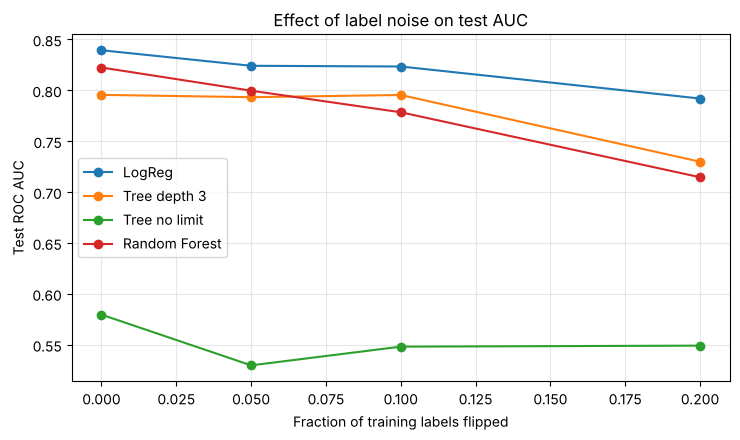

In [12]:
def make_models():
    return {
        "LogReg":        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
        "Tree depth 3":  DecisionTreeClassifier(max_depth=3, random_state=SEED),
        "Tree no limit": DecisionTreeClassifier(random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    }

def test_auc(model, Xtr, ytr):
    model.fit(Xtr, ytr)
    return roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

def flip_labels(y_series, fraction, rng):
    """Flip a fraction of the labels at random (0 -> 1, 1 -> 0)."""
    y_new = y_series.to_numpy().copy()
    n_flip = int(round(fraction * len(y_new)))
    idx = rng.choice(len(y_new), n_flip, replace=False)
    y_new[idx] = 1 - y_new[idx]
    return y_new

rng = np.random.default_rng(SEED)
fractions = [0, 0.05, 0.10, 0.20]
label_res = {}
for f in fractions:
    reps = 1 if f == 0 else 5
    scores = {name: [] for name in make_models()}
    for _ in range(reps):
        y_noisy = flip_labels(y_train, f, rng)
        for name, model in make_models().items():
            scores[name].append(test_auc(model, X_train, y_noisy))
    label_res[f] = {name: np.mean(v) for name, v in scores.items()}
label_df = pd.DataFrame(label_res).T
label_df.index.name = "label noise"
print(label_df.round(4))

label_df.plot(marker="o", figsize=(7.5, 4.5))
plt.ylabel("Test ROC AUC"); plt.xlabel("Fraction of training labels flipped")
plt.title("Effect of label noise on test AUC"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


### Task 5.2 — Feature noise
Add Gaussian noise to the **train** values of `age`, `avg_glucose_level` and `bmi`: `noise = random normal × (column std) × level`. Levels 0, 0.5, 1, 2; five repeats; test set untouched. Same kind of table and plot. (If you scale for Logistic Regression, fit the scaler on the noisy training data.)

                     LogReg  Tree depth 3  Tree no limit  Random Forest
feature noise level                                                    
0.0                  0.8394        0.7956         0.5797         0.8224
0.5                  0.8326        0.8121         0.5661         0.8159
1.0                  0.8077        0.7703         0.5371         0.7851
2.0                  0.7637        0.6853         0.5200         0.7358


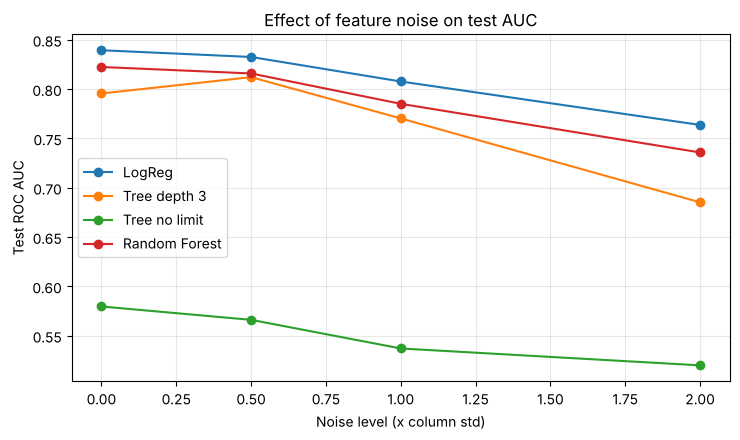

In [13]:
noisy_cols = ["age", "avg_glucose_level", "bmi"]
col_std = X_train[noisy_cols].std()

def add_feature_noise(X_df, level, rng):
    Xn = X_df.copy()
    for c in noisy_cols:
        Xn[c] = Xn[c] + rng.normal(size=len(Xn)) * col_std[c] * level
    return Xn

rng = np.random.default_rng(SEED)
levels = [0, 0.5, 1, 2]
feat_res = {}
for lev in levels:
    reps = 1 if lev == 0 else 5
    scores = {name: [] for name in make_models()}
    for _ in range(reps):
        Xn = add_feature_noise(X_train, lev, rng)          # test set stays untouched
        for name, model in make_models().items():          # LogReg pipeline refits its scaler on the noisy train data
            scores[name].append(test_auc(model, Xn, y_train))
    feat_res[lev] = {name: np.mean(v) for name, v in scores.items()}
feat_df = pd.DataFrame(feat_res).T
feat_df.index.name = "feature noise level"
print(feat_df.round(4))

feat_df.plot(marker="o", figsize=(7.5, 4.5))
plt.ylabel("Test ROC AUC"); plt.xlabel("Noise level (x column std)")
plt.title("Effect of feature noise on test AUC"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


### Task 5.3 — SMOTE and noisy labels
Flip 10% of the training labels (3 different random draws). For Logistic Regression and Random Forest compare **PR AUC and ROC AUC with and without SMOTE** (SMOTE applied after the noise is added).

In [14]:
rng = np.random.default_rng(SEED)
rows = []
for draw in range(3):
    y_noisy = pd.Series(flip_labels(y_train, 0.10, rng), index=X_train.index)
    for mname, kind in [("LogReg", "LogReg"), ("RandomForest", "RF")]:
        for use_smote in [False, True]:
            Xtr = X_train_s if mname == "LogReg" else X_train
            Xte = X_test_s if mname == "LogReg" else X_test
            # note: scaled copy was fitted on the clean train features; labels are the only thing damaged here
            if use_smote:
                Xr, yr = SMOTE(random_state=SEED).fit_resample(Xtr, y_noisy)     # SMOTE AFTER the noise
            else:
                Xr, yr = Xtr, y_noisy
            m = evaluate(make_model(kind), Xr, yr, Xte, y_test)
            rows.append({"draw": draw, "Model": mname, "SMOTE": "with" if use_smote else "without",
                         "ROC AUC": m["ROC AUC"], "PR AUC": m["PR AUC"]})
noise_smote = pd.DataFrame(rows)
summary53 = noise_smote.groupby(["Model", "SMOTE"])[["ROC AUC", "PR AUC"]].agg(["mean", "std"])
print(summary53.round(4))

# clean-label reference from Task 4.1 for comparison
ref = res41[res41["Method"].isin(["none", "SMOTE"])][["Model", "Method", "ROC AUC", "PR AUC"]]
print("\nReference with CLEAN labels (Task 4.1):")
print(ref.round(4).to_string(index=False))


                     ROC AUC          PR AUC        
                        mean     std    mean     std
Model        SMOTE                                  
LogReg       with     0.8051  0.0238  0.2269  0.0271
             without  0.8105  0.0167  0.2321  0.0278
RandomForest with     0.6791  0.0250  0.1213  0.0218
             without  0.7431  0.0236  0.1827  0.0277

Reference with CLEAN labels (Task 4.1):
       Model Method  ROC AUC  PR AUC
      LogReg   none   0.8394  0.2692
      LogReg  SMOTE   0.8406  0.2876
RandomForest   none   0.8224  0.2255
RandomForest  SMOTE   0.7977  0.2290


**Question 5.1:** Which model is most damaged by noise and which is most stable? Quote numbers at the highest noise level and explain using what you learned in Part 2.

**Question 5.2:** Which hurts more here — label noise or feature noise of a comparable level? Give a short reason.

**Question 5.3:** What did SMOTE do to each model when the labels were noisy? Explain why SMOTE can amplify label noise.

**Your answer:**

**Q5.1.** With 20% label noise, Random Forest is damaged most: test AUC falls from 0.822 to 0.715 (-0.108). The depth-3 tree falls from 0.796 to 0.730 (-0.066), and Logistic Regression from 0.839 to 0.792 (-0.047), so **Logistic Regression is the most stable of the useful models**. The tree with no depth limit changes the least (0.580 to 0.549), but only because it was already close to random guessing before any noise was added. With feature noise at level 2, the depth-3 tree is hit hardest (0.796 to 0.685, -0.110), then Random Forest (0.822 to 0.736, -0.087), and Logistic Regression is again the most stable (0.839 to 0.764, -0.076). This matches Part 2: flexible, high-variance models (deep trees and forests) fit the noise itself, while Logistic Regression has only 15 coefficients (high bias, low variance), so random errors mostly average out. The shallow tree suffers from feature noise because its few split thresholds on `age` and `avg_glucose_level` are exactly what the noise disturbs.

**Q5.2.** It depends on the model, so neither is always worse. At the highest levels (20% label noise against feature noise level 2), feature noise hurts Logistic Regression (0.792 against 0.764) and the depth-3 tree (0.730 against 0.685) more, because noise as large as twice the standard deviation of `age`, the strongest predictor, destroys the main signal in all training rows. Label noise hurts Random Forest more (0.715 against 0.736) because the forest memorises the wrong labels. Averaged over the three useful models, feature noise at level 2 is slightly worse (mean AUC 0.728 against 0.746), but the two are not exactly comparable, so I would not claim a strong difference.

**Q5.3.** With 10% noisy labels, SMOTE did not help either model. Logistic Regression changed little (ROC AUC 0.811 to 0.805, PR AUC 0.232 to 0.227, within the draw-to-draw standard deviation of 0.02 to 0.03). Random Forest got much worse (ROC AUC 0.743 to 0.679, PR AUC 0.183 to 0.121). SMOTE can amplify label noise because it builds new "stroke" points between existing stroke points. After flipping 10% of the labels, about 389 healthy patients become "stroke" while about 20 real strokes disappear, so roughly two of every three "stroke" rows are now wrong. SMOTE then interpolates between these wrong points and creates thousands of synthetic stroke patients in healthy regions, which multiplies the noise instead of averaging it out, and a flexible model like Random Forest memorises it.


---

## Part 6 — Final Decision and Conclusion
1. Choose your final approach for the hospital (model + rebalancing method or threshold). Build a final table on the test set comparing the default threshold 0.5 with your choice: Precision, Recall, F1, number of false alarms and number of missed strokes.
2. Write an **Executive Summary** (6–8 lines): what you chose, its recall and precision with numbers, the price paid, how you avoided leakage, and one limitation (think about only 50 stroke patients in the test set, and about how the threshold was chosen).

In [15]:
# Final approach: Logistic Regression (scaled, no resampling) + threshold chosen on TRAIN out-of-fold probabilities
def summarize(name, proba, thr):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Approach": name, "Threshold": round(thr, 4),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
            "Patients flagged": int(tp + fp), "False alarms (FP)": int(fp), "Missed strokes (FN)": int(fn)}

p_final = proba3["Logistic Regression"]                       # LR fitted on the training set only
lr_bal = LogisticRegression(max_iter=1000, random_state=SEED, class_weight="balanced").fit(X_train_s, y_train)

final = pd.DataFrame([
    summarize("LogReg, default threshold 0.5", p_final, 0.5),
    summarize("LogReg, chosen threshold (FINAL)", p_final, threshold),
    summarize("Reference: LogReg class_weight='balanced', 0.5", lr_bal.predict_proba(X_test_s)[:, 1], 0.5),
]).set_index("Approach")
print(final.round(4).to_string())

# how much can we trust a recall measured on only 50 strokes?  (Wilson 95% interval)
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

tp_final = int(round(final.loc["LogReg, chosen threshold (FINAL)", "Recall"] * y_test.sum()))
lo, hi = wilson(tp_final, int(y_test.sum()))
print(f"\nRecall {tp_final}/{int(y_test.sum())} = {tp_final / y_test.sum():.2f}; 95% interval: {lo:.2f} to {hi:.2f}")


                                                Threshold  Precision  Recall      F1  Patients flagged  False alarms (FP)  Missed strokes (FN)
Approach                                                                                                                                      
LogReg, default threshold 0.5                      0.5000     1.0000    0.02  0.0392                 1                  0                   49
LogReg, chosen threshold (FINAL)                   0.0509     0.1353    0.82  0.2323               303                262                    9
Reference: LogReg class_weight='balanced', 0.5     0.5000     0.1347    0.80  0.2305               297                257                   10

Recall 41/50 = 0.82; 95% interval: 0.69 to 0.90


**Executive Summary**

I chose a **Logistic Regression (scaled, no resampling) with a lowered decision threshold of 0.051**, picked from out-of-fold training probabilities so that recall is at least 80%. On the untouched test set (1,022 patients, 50 strokes) it finds **41 of 50 strokes (recall 0.82)** with **precision 0.135** (F1 0.232), compared with recall 0.02 at the default threshold 0.5. The price is that **303 patients (29.6%) are flagged, 262 of them false alarms** (about 6.4 per stroke found), and 9 strokes are still missed. Leakage was avoided by learning the median, the scaler and the threshold from the training data only (the threshold from out-of-fold predictions), and by never resampling the test set; the wrong-order SMOTE experiment, with its inflated AUC of 0.9955 against the honest 0.80, shows what the leak would have hidden. One limitation is that there are only 50 strokes in the test set, so recall of 0.82 has a 95% interval of roughly 0.69 to 0.90, and the threshold itself was tuned on only 199 training strokes, so a different split could move it.


**Final Reflection:** (a) What was the most surprising result in this lab? (b) If you had one more hour, what would you try next?

**Your answer:**

**(a)** The most surprising result was that the default Logistic Regression had 95.2% accuracy, better than the baseline, but found only 1 of 50 strokes, while the same model with just a lower threshold found 41. A close second was that the wrong-order SMOTE gave an AUC of 0.9955, while the correct order gave about 0.80, and that SMOTE actually made Random Forest worse instead of better.

**(b)** With one more hour I would (1) repeat the evaluation with repeated stratified cross-validation instead of one 50-stroke test set, so I could give an interval for every metric, (2) calibrate the probabilities and choose the threshold from the real cost of a missed stroke against a false alarm, and (3) try a gradient-boosted model with `class_weight` or sample weights to see whether it beats the simple Logistic Regression.
